In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from scipy.special import kv, gamma
from scipy.stats import norm
from scipy.optimize import minimize
from scipy.linalg import cholesky, cho_solve ,solve_triangular
from scipy.interpolate import Rbf
from mpl_toolkits.mplot3d import Axes3D  
from scipy.interpolate import RegularGridInterpolator
from scipy.interpolate import interp1d
import pandas as pd
from scipy.interpolate import LinearNDInterpolator
import itertools
import warnings
from scipy.stats import qmc
import matplotlib.tri as tri
from matplotlib.path import Path
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import spsolve
import time
import matplotlib as mpl
from IPython.display import clear_output
import random
import matplotlib.patches as patches
from scipy.sparse import coo_matrix
from joblib import Parallel, delayed
from IPython.display import clear_output
from tqdm import tqdm
import math
import torch
import gc 
import os

rng = np.random.RandomState(42)
warnings.filterwarnings("ignore")

# Define these constants globally or at the top of your file
INV_SQRT_2 = 1.0 / math.sqrt(2.0)
INV_SQRT_2PI = 1.0 / math.sqrt(2.0 * math.pi)
# Force numpy/scipy to use only 1 thread per worker
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

rng = np.random.RandomState(42)
warnings.filterwarnings("ignore")
# Force PyTorch to use only 1 thread per worker
torch.set_num_threads(1)

# --- OPTIMIZATION: Set PyTorch to float64 for GP numerical stability ---
torch.set_default_dtype(torch.float64)





In [9]:

# -----------------------------
# 1️⃣ Partition utilities
# -----------------------------
def divide_bounds(bounds, n_parts=2, mode='grid', axis=0):
    bounds = np.array(bounds, dtype=float)
    n_dim = bounds.shape[0]
    n_parts = int(n_parts)
    
    grid_points = [np.linspace(bounds[d,0], bounds[d,1], n_parts+1) for d in range(n_dim)]
    
    if n_parts == 1:
        return [bounds], grid_points
    
    region_bounds = []
    if mode == 'grid':
        # Vectorized generation of all hyper-rectangles
        lows = [grid_points[d][:-1] for d in range(n_dim)]
        highs = [grid_points[d][1:] for d in range(n_dim)]
        
        mesh_lows = np.array(np.meshgrid(*lows, indexing='ij')).reshape(n_dim, -1).T
        mesh_highs = np.array(np.meshgrid(*highs, indexing='ij')).reshape(n_dim, -1).T
        
        region_bounds = list(np.stack((mesh_lows, mesh_highs), axis=-1))
            
    elif mode == 'axis':
        for i in range(n_parts):
            b = bounds.copy()
            b[axis,0] = grid_points[axis][i]
            b[axis,1] = grid_points[axis][i+1]
            region_bounds.append(b)
            
    return region_bounds, grid_points

def region_index(X, grid_points):
    X = np.atleast_2d(X)
    n_dim = X.shape[1]
    n_parts = len(grid_points[0])-1
    indices = []
    
    for d in range(n_dim):
        idx_d = np.digitize(X[:,d], grid_points[d][1:-1], right=True)
        idx_d = np.clip(idx_d, 0, n_parts-1)
        indices.append(idx_d)
        
    multi_idx = np.vstack(indices).T
    flat_idx = np.ravel_multi_index(multi_idx.T, dims=[n_parts]*n_dim)
    return flat_idx

# -----------------------------
# 2️⃣ Matern kernel
# -----------------------------
def matern_kernel(X1, X2, l=1.0, nu=2.5):
    X1, X2 = np.atleast_2d(X1), np.atleast_2d(X2)
    r = cdist(X1/l, X2/l)
    
    if nu == 0.5:
        return np.exp(-r)
    elif nu == 1.5:
        sqrt3_r = np.sqrt(3) * r
        return (1 + sqrt3_r) * np.exp(-sqrt3_r)
    elif nu == 2.5:
        sqrt5_r = np.sqrt(5) * r
        return (1 + sqrt5_r + 5/3 * r**2) * np.exp(-sqrt5_r)
    else:
        sqrt_2nu_r = np.sqrt(2 * nu) * r
        K = (2**(1-nu)/gamma(nu)) * (sqrt_2nu_r**nu) * kv(nu, sqrt_2nu_r)
        K[r == 0] = 1.0
        return K

# -----------------------------
# 3️⃣ GP fast prediction
# -----------------------------
def gp_predict_fast(x_train, x_test, kernel_func, L, alpha, **kernel_args):
    K_s = kernel_func(x_train, x_test, **kernel_args)
    mu = K_s.T @ alpha 
    
    v = solve_triangular(L, K_s, lower=True)
    var = 1.0 - np.sum(v**2, axis=0) 
    return mu.flatten(), np.sqrt(np.maximum(var, 0.0))

# -----------------------------
# 4️⃣ Sigma estimator
# -----------------------------
def sigma_estimator(X, y, kernel, **kernel_args):
    N = len(X)
    K = kernel(X, X, **kernel_args)
    
    trace_K = np.trace(K)
    jitter = 1e-6 * trace_K / N  
    
    try:
        K_reg = K + jitter * np.eye(N)
        L = cholesky(K_reg, lower=True)
        alpha = cho_solve((L, True), y)
        sigma2 = y @ alpha / N 
        
        if sigma2 > 0 and not np.isnan(sigma2):
            return np.sqrt(sigma2)
    except np.linalg.LinAlgError:
        pass
    
    return np.std(y)

# -----------------------------
# 5️⃣ Partition tree
# -----------------------------
def partition_tree(f, N, initial_bounds, kernel, kernel_args, sigma_estimator, iter_max=3, figg=False):
    n_dim = initial_bounds.shape[0]
    X = np.random.uniform(initial_bounds[:,0], initial_bounds[:,1], (max(N, 5), n_dim))
    y = f(X).flatten()
    
    
    root_sigma = sigma_estimator(X, y, kernel, **kernel_args)
    queue = [(initial_bounds, root_sigma, 0)]
    iterations_history = {i: [] for i in range(iter_max+1)}
    iterations_history[0].append(initial_bounds)
    final_leaves = []
    threshold = 1.35

    # --- OPTIMIZATION: Memoize sigma calculations ---
    sigma_cache = {}
    def get_cached_sigma(mask, fallback_sigma):
        idx_tuple = tuple(np.nonzero(mask)[0])
        if idx_tuple in sigma_cache:
            return sigma_cache[idx_tuple]
        
        if len(idx_tuple) >= 3:
            val = sigma_estimator(X[mask], y[mask], kernel, **kernel_args)
        else:
            val = fallback_sigma
            
        sigma_cache[idx_tuple] = val
        return val

    while queue:
        curr_b, curr_s, depth = queue.pop(0)
        
        if depth >= iter_max:
            final_leaves.append(curr_b)
            continue
        
        axis_scores = []
        for axis in range(n_dim):
            children, grid_pts = divide_bounds(curr_b, n_parts=2, mode='axis', axis=axis)
            idx = np.digitize(X[:, axis], grid_pts[axis][1:-1], right=True)
            idx = np.clip(idx, 0, len(children)-1)

            child_sigmas = []
            for r in range(len(children)):
                mask = (idx == r)
                sig_child = get_cached_sigma(mask, curr_s)
                child_sigmas.append(sig_child)

            axis_scores.append({
                'axis': axis,
                'max_sigma': max(child_sigmas)
            })

        axis_scores.sort(key=lambda x: x['max_sigma'], reverse=True)
        # ---  Only split the single axis with the highest sigma variation ---
        
        num_axes_to_split = min(3, n_dim - 1)
        chosen_axes = [info['axis'] for info in axis_scores[:num_axes_to_split]]

        intervals_per_dim = []
        for d in range(n_dim):
            if d in chosen_axes:
                mid = (curr_b[d, 0] + curr_b[d, 1]) / 2.0
                intervals_per_dim.append([(curr_b[d, 0], mid), (mid, curr_b[d, 1])])
            else:
                intervals_per_dim.append([(curr_b[d, 0], curr_b[d, 1])])

        multi_children = []
        for combo in itertools.product(*intervals_per_dim):
            child_b = np.empty_like(curr_b)
            for d, (low, high) in enumerate(combo):
                child_b[d, 0] = low
                child_b[d, 1] = high
            multi_children.append(child_b)

        multi_sigmas = []
        for child_b in multi_children:
            mask = np.all((X >= child_b[:, 0]) & (X <= child_b[:, 1]), axis=1)
            sig_child = get_cached_sigma(mask, curr_s)
            multi_sigmas.append(sig_child)

        ratio = max(multi_sigmas) / (min(multi_sigmas) + 1e-12)
        
        if ratio > threshold:
            for child_b, child_s in zip(multi_children, multi_sigmas):
                queue.append((child_b, child_s, depth+1))
                iterations_history[depth+1].append(child_b)
        else:
            final_leaves.append(curr_b)
            for d in range(depth+1, iter_max+1):
                iterations_history[d].append(curr_b)
                
    if figg:
        fig, axes = plt.subplots(1, iter_max + 1, figsize=(20, 5))
        for d, ax_plot in enumerate(axes):
            if d not in iterations_history: continue
            ax_plot.set_title(f"Iteration {d}")
            ax_plot.set_xlim(initial_bounds[0])
            if n_dim > 1: ax_plot.set_ylim(initial_bounds[1])
            ax_plot.set_aspect('equal')
    
            for b in iterations_history[d]:
                width = b[0, 1] - b[0, 0]
                height = b[1, 1] - b[1, 0] if n_dim > 1 else 1.0
                y_coord = b[1, 0] if n_dim > 1 else 0.0
                
                rect = patches.Rectangle((b[0, 0], y_coord), width, height,
                                         linewidth=2, edgecolor='black', facecolor='none')
                ax_plot.add_patch(rect)
            
            if n_dim > 1:
                ax_plot.scatter(X[:, 0], X[:, 1], s=10, c='blue', alpha=0.5)
            else:
                ax_plot.scatter(X[:, 0], np.zeros_like(X[:, 0]), s=10, c='blue', alpha=0.5)
    
        plt.tight_layout()
        plt.show()

    return iterations_history[iter_max]  

# -----------------------------
# 6️⃣ General BO with either partition method
# -----------------------------
def bayesian_optimization_partition(
        x_train, y_train, f_true, bounds,
        kernel_func, kernel_args,
        n_iter=10, partition_method='tree', tree_depth=3,
        noise_var=1e-8, sig=True,
        acq_type='ei', acq_params={},
        n_candidates_per_region=256, 
        sigma_estimator=None,
        n_parts_fixed=2):
    
    x_train = np.atleast_2d(x_train)
    y_train = np.atleast_1d(y_train).flatten()
    n_dim = x_train.shape[1]
    
    # 1️⃣ BUILD PARTITIONS
    if partition_method == 'tree':
        leaves_bounds = partition_tree(
            lambda X: f_true(X), N=1000, initial_bounds=bounds,
            kernel=kernel_func, kernel_args=kernel_args,
            sigma_estimator=sigma_estimator, iter_max=tree_depth
        )
    elif partition_method == 'fixed':
        leaves_bounds, _ = divide_bounds(bounds, n_parts=n_parts_fixed, mode='grid')
    else:
        raise ValueError("Unknown partition_method")
    
    n_regions = len(leaves_bounds)
    region_counter = np.zeros(n_regions, dtype=int)
    sigma_per_region = np.ones(n_regions)
    sampler = qmc.Sobol(d=n_dim, scramble=True)
    
    def compute_acq_values(x_eval, region_indices):
        x_eval = np.atleast_2d(x_eval)
        mu, base_std = gp_predict_fast(x_train, x_eval, kernel_func, L, alpha, **kernel_args)
        
        sig_local = sigma_per_region[region_indices]
        sigma_eff = np.maximum(base_std * sig_local, 1e-15)
        y_best = np.min(y_train)
        
        if acq_type == 'ei':
            xi = acq_params.get('xi', 0.01)
            Z = (y_best - mu - xi) / sigma_eff
            return (y_best - mu - xi) * norm.cdf(Z) + sigma_eff * norm.pdf(Z)
        elif acq_type == 'pi':
            xi = acq_params.get('xi', 0.01)
            Z = (y_best - mu - xi) / sigma_eff
            return norm.cdf(Z)
        elif acq_type == 'lcb':
            beta = acq_params.get('beta', 2.0)
            return -(mu - beta * sigma_eff) 
        elif acq_type == 'ts':
            return -(mu + sigma_eff * np.random.randn(len(mu)))
        
        return -mu

    # --- OPTIMIZATION: Initialize region sigmas exactly once ---
    if sig:
        for r, b in enumerate(leaves_bounds):
            mask = np.all((x_train >= b[:, 0]) & (x_train <= b[:, 1]), axis=1)
            if np.sum(mask) >= 3:
                sigma_per_region[r] = sigma_estimator(x_train[mask], y_train[mask], kernel_func, **kernel_args)

    # 2️⃣ MAIN OPTIMIZATION LOOP
    for i in range(n_iter):
        K_full = kernel_func(x_train, x_train, **kernel_args)
        K_full[np.diag_indices_from(K_full)] += noise_var
        
        jitter = 1e-8
        while True:
            try:
                L = cholesky(K_full + np.eye(len(K_full)) * jitter, lower=True)
                break
            except np.linalg.LinAlgError:
                jitter *= 10
                if jitter > 1e-1: raise np.linalg.LinAlgError("Matrix non-invertible.")
        
        alpha = cho_solve((L, True), y_train)

        # 3️⃣ STEP A: BROAD SOBOL SEARCH
        Xcand_list, region_ids_list = [], []
        for r, b in enumerate(leaves_bounds):
            sobol_pts = sampler.random(n_candidates_per_region)
            # --- OPTIMIZATION: Vectorized scaling ---
            scale = b[:, 1] - b[:, 0]
            offset = b[:, 0]
            samples = sobol_pts * scale + offset
            
            Xcand_list.append(samples)
            region_ids_list.append(np.full(n_candidates_per_region, r))
            
        X_sobol = np.vstack(Xcand_list)
        R_sobol = np.concatenate(region_ids_list)
        
        acq_sobol = compute_acq_values(X_sobol, R_sobol)

        # 4️⃣ STEP B: MULTI-START LOCAL REFINEMENT
        n_starts = 3
        top_indices = np.argsort(acq_sobol)[-n_starts:][::-1]
        
        best_refined_x = None
        best_refined_acq = -np.inf
        final_region_idx = None

        for idx in top_indices:
            x_seed = X_sobol[idx]
            r_idx = R_sobol[idx] 
            target_bounds = leaves_bounds[r_idx]
            
            def min_obj(x):
                val = compute_acq_values(x.reshape(1, -1), [r_idx])
                return -float(np.asarray(val).item())

            res = minimize(
                fun=min_obj,
                x0=x_seed,
                bounds=[(target_bounds[d, 0], target_bounds[d, 1]) for d in range(n_dim)],
                method='L-BFGS-B'
            )
            
            current_acq = -res.fun
            if current_acq > best_refined_acq:
                best_refined_acq = current_acq
                best_refined_x = res.x
                final_region_idx = r_idx

        # 5️⃣ UPDATE TRAIN SET
        x_next = best_refined_x.reshape(1, -1)
        y_next = f_true(x_next).flatten()
        
        x_train = np.vstack((x_train, x_next))
        y_train = np.append(y_train, y_next)
        
        region_counter[final_region_idx] += 1
        
        # --- OPTIMIZATION: Lazy sigma update ---
        if sig:
            b = leaves_bounds[final_region_idx]
            mask = np.all((x_train >= b[:, 0]) & (x_train <= b[:, 1]), axis=1)
            if np.sum(mask) >= 3:
                sigma_per_region[final_region_idx] = sigma_estimator(
                    x_train[mask], y_train[mask], kernel_func, **kernel_args
                )
        
        if i % 5 == 0:
            sampler = qmc.Sobol(d=n_dim, scramble=True)

    return x_train, y_train, sigma_per_region, region_counter

In [10]:


def evaluate_single_config(seed, objective_function, bounds, config, n_init, d, n_iter, 
                           kernel_args, noise_var, tree_depth, sigma_estimator, 
                           n_candidates=256):
    rng = np.random.default_rng()

    # Initial shared design
    # # a, b = bounds[0][0], bounds[0][1]'1-s2.0-S0021999121006835-main.pdf
    # x_train_init = qmc.scale(sample_raw, bounds_schwefel_nd[:, 0], bounds_schwefel_nd[:, 1])
    # y_train_init = objective_function(x_train_init).reshape(-1, 1)
    sampler = qmc.Sobol(d=d, scramble=True, seed=seed)
    sample_raw = sampler.random(n_init)
    
    # Correct scaling using the fix from the previous error
    l_bounds = bounds[:, 0]
    u_bounds = bounds[:, 1]
    x_train_init = qmc.scale(sample_raw, l_bounds, u_bounds)
    # from scipy.stats import qmc

    # Define the sampler (d is your number of dimensions)
    # sampler = qmc.Sobol(d=d, scramble=True, seed=rng)
    # Generate samples in the range [0, 1]
    # sample_raw = sampler.random(n_init)

    # Scale to your specific bounds [a, b]
    # x_train_init = qmc.scale(sample_raw, bounds[0], bounds[1])
    y_train_init = objective_function(x_train_init).reshape(-1, 1)

    label, partition_method, n_parts_fixed, sig_on, acq_name, params = config

    x_out, y_out, _, _ = bayesian_optimization_partition(
        x_train_init.copy(), 
        y_train_init.copy(), 
        objective_function, 
        bounds,
        matern_kernel, 
        kernel_args,
        n_iter=n_iter, 
        partition_method=partition_method,
        tree_depth=tree_depth,
        noise_var=noise_var,
        sig=sig_on,
        acq_type=acq_name,
        acq_params=params,
        n_candidates_per_region=n_candidates,
        sigma_estimator=sigma_estimator,
        n_parts_fixed=n_parts_fixed
    )
    
    # Store "best so far"
    history = np.zeros(n_iter + 1)
    for t in range(n_iter + 1):
        history[t] = np.min(y_out[:n_init + t])
        
    # FORCE Python to dump all the heavy matrices from RAM instantly
    gc.collect()
    
    return seed, label, history




In [11]:

def plot_grouped_comparison(histories_dict, n_seeds=30, save_path=None):
    """
    Publication-quality grouped comparison across acquisition functions.
    Includes 95% confidence intervals and improved visual design.
    """

    # -----------------------------
    # Global Style (Paper Ready)
    # -----------------------------
    mpl.rcParams.update({
        "font.family": "serif",
        "font.size": 12,
        "axes.titlesize": 13,
        "axes.labelsize": 12,
        "legend.fontsize": 10,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.linewidth": 1.1,
        "lines.linewidth": 2.4,
        "figure.dpi": 200,
        "savefig.dpi": 400,
    })

    groups = ['EI', 'PI', 'LCB', 'TS']
    methods = ["Classic BO", "IBO_1","IBO_4", "IBO_P"]

    # Single row with 4 subplots
    fig, axes = plt.subplots(
        1, 4,
        figsize=(16, 5),  # Wider figure for single row
        sharex=True,
        sharey=True,
        constrained_layout=False
    )
    axes = axes.flatten()

    # Professional color palette (colorblind-safe)
    colors = {
        "Classic BO": "#1f77b4",
        "IBO_1": "#d62728",
        "IBO_4": "#ff7f0e",
        "IBO_P": "#2ca02c",
        
    }

    for i, acq in enumerate(groups):
        ax = axes[i]

        for method in methods:
            label = f"{method} - {acq}"
            data = histories_dict[label]

            mean = np.mean(data, axis=0)
            sem = np.std(data, axis=0) / np.sqrt(n_seeds)

            iters = np.arange(len(mean))

            # ---- Main curve ----
            ax.plot(
                iters,
                mean,
                label=method,
                color=colors[method],
                zorder=3
            )

            # ---- 95% Confidence Interval ----
            ax.fill_between(
                iters,
                mean - 1.96 * sem,
                mean + 1.96 * sem,
                color=colors[method],
                alpha=0.18,
                linewidth=0,
                zorder=2
            )

        # Clean panel styling
        ax.set_title(acq, fontweight='bold')
        ax.grid(alpha=0.25)
        ax.set_xlim(left=0)

        # Only set ylabel for first subplot
        if i == 0:
            ax.set_ylabel("Improvement")
        
        # Set xlabel for all subplots
        ax.set_xlabel("Iteration")

        # Add legend only to first subplot
        if i == 0:
            ax.legend(loc='best', frameon=False)

    plt.tight_layout()

    # Save as vector for publication
    if save_path is not None:
        plt.savefig(save_path, bbox_inches="tight", format="pdf", dpi=400)

    plt.show()


In [12]:
import ssl
import urllib.request

# Bypass SSL verification
ssl._create_default_https_context = ssl._create_unverified_context

import LassoBench

# Now this should download successfully
diabetes_bench = LassoBench.RealBenchmark(pick_data='diabetes', mf_opt='discrete_fidelity')

In [13]:


# ==========================================
# 1. Objective and Benchmark Setup
# ==========================================
# Initialize once
diabetes_bench = LassoBench.RealBenchmark(pick_data='diabetes', mf_opt='discrete_fidelity')
d_lasso = diabetes_bench.n_features 

def lasso_diabetes_objective(X):
    X = np.atleast_2d(X)
    # MUST scale: BO searches in [0, 1], but LassoBench expects [-1, 1]
    X_scaled = 2 * X - 1 
    
    # Return the raw loss directly since your BO loop minimizes (finds y_train_t.min())
    return np.array([diabetes_bench.evaluate(x) for x in X_scaled]).flatten()



In [14]:
# ==========================================
# 2. BO Parameters for Lasso
# ==========================================
bounds_lasso = np.array([[0.0, 1.0]] * d_lasso)
tree_depth = 3
n_init_lasso = 16 * d_lasso  
n_iter_lasso =400        
n_seeds = 30          

kernel_args_lasso = {'l': 0.3, 'nu': 2.5}
noise_var_lasso = 1e-6

# ==========================================
# 3. All Configurations (16 Total)
# ==========================================
configs_lasso = [
    # --- EI Group ---
    ("Classic BO - EI", 'fixed', 1,  False, 'ei', {'xi': 0.01}),
    ("IBO_1 - EI",      'fixed', 1,  True,  'ei', {'xi': 0.01}),
    ("IBO_4 - EI",      'fixed', 2,  True,  'ei', {'xi': 0.01}),
    ("IBO_P - EI",      'tree',  2,  True,  'ei', {'xi': 0.01}),
    
    # --- PI Group ---
    ("Classic BO - PI", 'fixed', 1,  False, 'pi', {'xi': 0.01}),
    ("IBO_1 - PI",      'fixed', 1,  True,  'pi', {'xi': 0.01}),
    ("IBO_4 - PI",      'fixed', 2,  True,  'pi', {'xi': 0.01}),
    ("IBO_P - PI",      'tree',  2,  True,  'pi', {'xi': 0.01}),
    
    # --- LCB Group ---
    ("Classic BO - LCB",'fixed', 1,  False, 'lcb', {'beta': 3.0}),
    ("IBO_1 - LCB",     'fixed', 1,  True,  'lcb', {'beta': 3.0}),
    ("IBO_4 - LCB",     'fixed', 2,  True,  'lcb', {'beta': 3.0}),
    ("IBO_P - LCB",     'tree',  2,  True,  'lcb', {'beta': 3.0}),
    
    # --- TS Group ---
    ("Classic BO - TS", 'fixed', 1,  False, 'ts', {}), 
    ("IBO_1 - TS",      'fixed', 1,  True,  'ts', {}),
    ("IBO_4 - TS",      'fixed', 2,  True,  'ts', {}),
    ("IBO_P - TS",      'tree',  2,  True,  'ts', {})
]


In [15]:
# ==========================================
# 4. Method-by-Method Parallel Execution
# ==========================================
# Initialize dictionary for the plotter
histories_lasso = {c[0]: np.zeros((n_seeds, n_iter_lasso + 1)) for c in configs_lasso}

start = time.perf_counter()

for config in configs_lasso:
    label = config[0]
    print(f"\n🚀 Starting: {label}")
    print(f"   Running {n_seeds} seeds in parallel ({n_iter_lasso} iterations each)...")
    
    # Execute ONLY the current config across all seeds in parallel
    results = Parallel(n_jobs=4)(
        delayed(evaluate_single_config)(
            seed, lasso_diabetes_objective, bounds_lasso, config, 
            n_init_lasso, d_lasso, n_iter_lasso, 
            kernel_args_lasso, noise_var_lasso, tree_depth, 
            sigma_estimator, n_candidates=256
        ) for seed in tqdm(range(n_seeds), desc=f"Optimizing {label}", leave=False)
    )
    
    # Store the results for this method
    for seed, returned_label, history in results:
        histories_lasso[label][seed, :] = history
        
    # Optional: clean up memory aggressively after each method finishes
    gc.collect()

end = time.perf_counter()
print(f"\n✅ Total Execution time: {end - start:.2f} seconds")




🚀 Starting: Classic BO - EI
   Running 30 seeds in parallel (400 iterations each)...



🚀 Starting: IBO_1 - EI
   Running 30 seeds in parallel (400 iterations each)...



🚀 Starting: IBO_4 - EI
   Running 30 seeds in parallel (400 iterations each)...



🚀 Starting: IBO_P - EI
   Running 30 seeds in parallel (400 iterations each)...



🚀 Starting: Classic BO - PI
   Running 30 seeds in parallel (400 iterations each)...



🚀 Starting: IBO_1 - PI
   Running 30 seeds in parallel (400 iterations each)...


... (7 outputs left out)


🚀 Starting: IBO_1 - TS
   Running 30 seeds in parallel (400 iterations each)...



🚀 Starting: IBO_4 - TS
   Running 30 seeds in parallel (400 iterations each)...



🚀 Starting: IBO_P - TS
   Running 30 seeds in parallel (400 iterations each)...



✅ Total Execution time: 10636.53 seconds


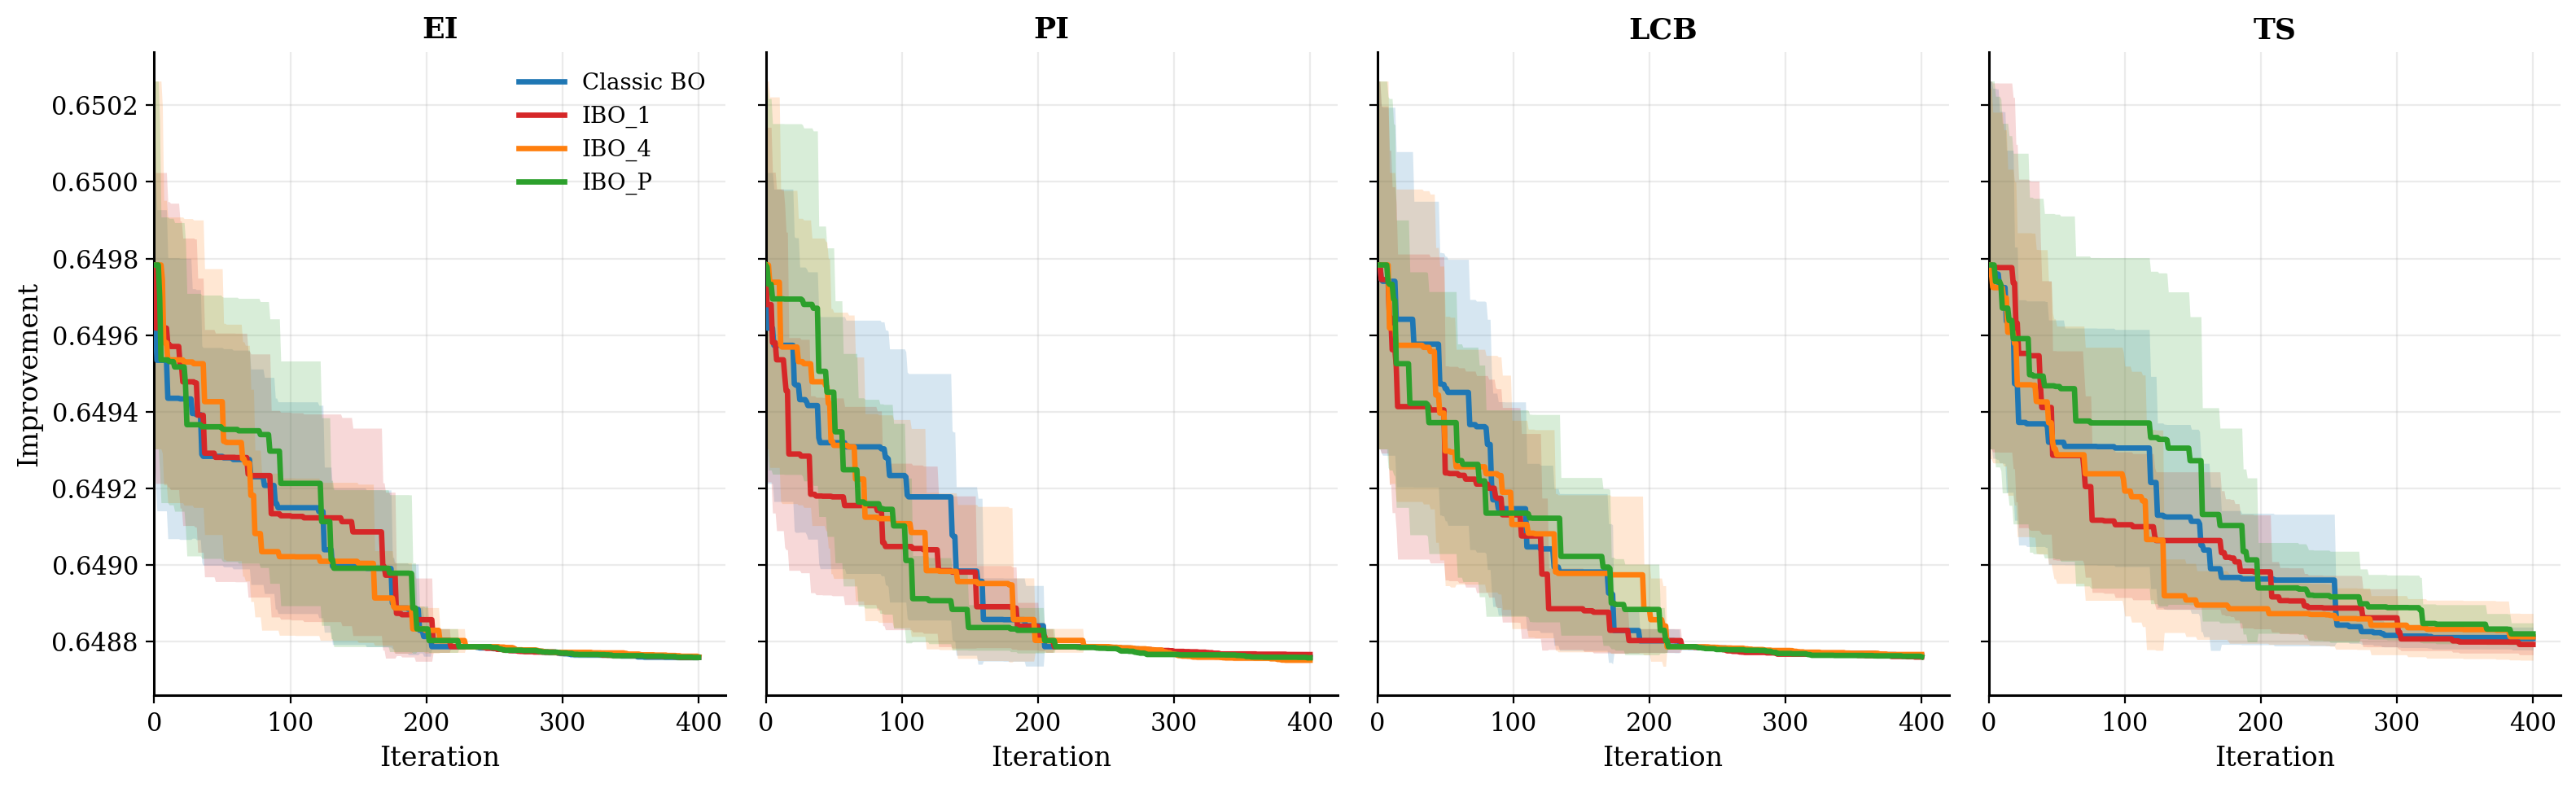

In [19]:
# Plot the results
plot_grouped_comparison(histories_lasso,save_path="lasso_diabetes_comparison.pdf")